In [1]:
import pickle
import pandas as pd
import numpy as np

# Load chemical-space master table
with open("Caco2_chemical_space_master.pkl", "rb") as f:
    chemical_space_master = pickle.load(f)

print("=== Chemical-Space Master Dataset ===")
print("Rows:", len(chemical_space_master))
print("Columns:", chemical_space_master.columns.tolist())

print("\nFirst 5 rows:")
display(chemical_space_master.head())

=== Chemical-Space Master Dataset ===
Rows: 20449
Columns: ['canonical_smiles', 'log10_median_papp', 'Morgan_distance', 'RDKit_distance', 'Hybrid_distance']

First 5 rows:


,canonical_smiles,log10_median_papp,Morgan_distance,RDKit_distance,Hybrid_distance
0,Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1,1.047664,0.200000,2.864551,0.539836
1,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,0.542825,0.575000,6.721927,1.051168
2,Brc1ccc(-c2nnc(N3CCN(c4ccccn4)CC3)o2)cc1,0.770852,0.276596,6.929545,1.041043
3,Brc1ccc(C2(CC3CCCC3)c3ccccc3-c3nccn32)cn1,1.397940,0.321429,5.158925,0.798420
4,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1.491362,0.188679,2.751963,0.535231


# Prepare the prediction target

In [2]:
# Prediction target
y = chemical_space_master["log10_median_papp"].values

print("=== Prediction Target Quality Check ===")
print("Number of molecules:", len(y))
print("Missing values:", np.isnan(y).sum())
print("Infinite values:", np.isinf(y).sum())

print("\nTarget statistics:")
print(pd.Series(y).describe())

=== Prediction Target Quality Check ===
Number of molecules: 20449
Missing values: 0
Infinite values: 0

Target statistics:
count    20449.000000
mean         0.852952
std          0.820542
min         -4.000000
25%          0.380211
50%          0.982271
75%          1.361728
max          4.444661
dtype: float64


# Load the saved Morgan representation

In [3]:
import pickle

with open("caco2_morgan_chemical_space.pkl", "rb") as f:
    morgan_data = pickle.load(f)

print("Keys:")
print(morgan_data.keys())

Keys:
dict_keys(['df_cs', 'X_morgan', 'nearest_indices', 'nearest_similarities', 'nearest_distances'])


# Verify alignment

In [4]:
X_morgan = morgan_data["X_morgan"]

print("=== Morgan Model Feature Check ===")
print("X_morgan shape:", X_morgan.shape)
print("Target length:", len(y))

print("\nShape aligned:",
      X_morgan.shape[0] == len(y))

=== Morgan Model Feature Check ===
X_morgan shape: (20449, 2048)
Target length: 20449

Shape aligned: True


# Create the train/test split

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_morgan,
    y,
    test_size=0.20,
    random_state=42
)

print("=== Train/Test Split ===")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

=== Train/Test Split ===
X_train: (16359, 2048)
X_test : (4090, 2048)
y_train: (16359,)
y_test : (4090,)


# Train the Random Forest baseline

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf_model = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest baseline trained successfully.")

Random Forest baseline trained successfully.


# Generate Prediction

In [7]:
y_pred = rf_model.predict(X_test)

print("Predictions generated.")
print("Number of predictions:", len(y_pred))

Predictions generated.
Number of predictions: 4090


# Baseline performance

In [9]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("=== Random Forest Baseline Performance ===")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

=== Random Forest Baseline Performance ===
MAE  : 0.3842
RMSE : 0.5483
R²   : 0.5571


# Molecule-level prediction error

In [10]:
# Calculate absolute prediction error for each test molecule

test_error = np.abs(y_test - y_pred)

print("=== Prediction Error ===")
print("Number of test molecules:", len(test_error))
print("Mean absolute error:", test_error.mean())
print("Median absolute error:", np.median(test_error))
print("Minimum error:", test_error.min())
print("Maximum error:", test_error.max())

=== Prediction Error ===
Number of test molecules: 4090
Mean absolute error: 0.3842178891876951
Median absolute error: 0.2680053574950802
Minimum error: 1.3322676295501878e-14
Maximum error: 4.237297359289885


# Align chemical-space distance with prediction error

In [11]:
# Preserve the original molecule indices used in the train/test split

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42
)

print("Training indices:", len(train_idx))
print("Test indices:", len(test_idx))
print("First 10 test indices:", test_idx[:10])

Training indices: 16359
Test indices: 4090
First 10 test indices: [ 2300 10519  4148 15808  9161 14967 17622  4186 10502 15242]


# Combine distances with prediction error

In [12]:
# Extract chemical-space information for the exact test molecules

test_analysis = chemical_space_master.iloc[test_idx].copy()

# Add model predictions and molecule-level absolute error
test_analysis["y_true"] = y_test
test_analysis["y_pred"] = y_pred
test_analysis["absolute_error"] = test_error

print("=== Test Analysis Dataset ===")
print("Rows:", len(test_analysis))
print("Columns:", test_analysis.shape[1])

print("\nColumns:")
print(test_analysis.columns.tolist())

print("\nMissing values:")
print(test_analysis.isna().sum())

=== Test Analysis Dataset ===
Rows: 4090
Columns: 8

Columns:
['canonical_smiles', 'log10_median_papp', 'Morgan_distance', 'RDKit_distance', 'Hybrid_distance', 'y_true', 'y_pred', 'absolute_error']

Missing values:
canonical_smiles     0
log10_median_papp    0
Morgan_distance      0
RDKit_distance       0
Hybrid_distance      0
y_true               0
y_pred               0
absolute_error       0
dtype: int64


# First look at distance–error relationships

In [13]:
# Correlation between chemical-space distance and prediction error

distance_error_corr = test_analysis[
    [
        "Morgan_distance",
        "RDKit_distance",
        "Hybrid_distance",
        "absolute_error"
    ]
].corr(method="spearman")

print("=== Spearman Correlation: Chemical-Space Distance vs Prediction Error ===")
print(distance_error_corr["absolute_error"].sort_values(ascending=False))

=== Spearman Correlation: Chemical-Space Distance vs Prediction Error ===
absolute_error     1.000000
RDKit_distance     0.234328
Hybrid_distance    0.209847
Morgan_distance    0.177002
Name: absolute_error, dtype: float64


# Distance bins
This is important because a correlation alone can hide the actual behavior. We'll divide molecules into chemical-space distance quantiles and calculate the mean/median prediction error in each group.
For each representation separately, we'll use the same test molecules and create 5 distance bins (quintiles).

In [14]:
# Create quintile-based chemical-space distance groups

for distance_col in [
    "Morgan_distance",
    "RDKit_distance",
    "Hybrid_distance"
]:
    
    bin_col = distance_col.replace("_distance", "_bin")
    
    test_analysis[bin_col] = pd.qcut(
        test_analysis[distance_col],
        q=5,
        labels=[
            "Q1 (closest)",
            "Q2",
            "Q3",
            "Q4",
            "Q5 (most distant)"
        ],
        duplicates="drop"
    )

print("Distance bins created successfully.")

Distance bins created successfully.


In [15]:
for distance_col in [
    "Morgan_distance",
    "RDKit_distance",
    "Hybrid_distance"
]:
    
    bin_col = distance_col.replace("_distance", "_bin")
    
    print(f"\n=== {distance_col} vs Prediction Error ===")
    
    summary = test_analysis.groupby(
        bin_col,
        observed=True
    )["absolute_error"].agg(
        ["count", "mean", "median", "std"]
    )
    
    print(summary)


=== Morgan_distance vs Prediction Error ===
                   count      mean    median       std
Morgan_bin                                            
Q1 (closest)         823  0.324902  0.203168  0.364031
Q2                   826  0.347329  0.243267  0.358989
Q3                   806  0.362498  0.254542  0.347823
Q4                   817  0.398945  0.289953  0.413284
Q5 (most distant)    818  0.487839  0.378185  0.443041

=== RDKit_distance vs Prediction Error ===
                   count      mean    median       std
RDKit_bin                                             
Q1 (closest)         818  0.284216  0.192853  0.293183
Q2                   818  0.311383  0.205055  0.350081
Q3                   818  0.393780  0.294537  0.384463
Q4                   818  0.418755  0.305542  0.404835
Q5 (most distant)    818  0.512955  0.392166  0.460957

=== Hybrid_distance vs Prediction Error ===
                   count      mean    median       std
Hybrid_bin                               

- So as molecules become more distant from their nearest neighbors in chemical space, prediction error increases.


- 2. The most interesting observation
- RDKit descriptors show the strongest distance-dependent increase in error.

# Statistical test + effect size

Use the Mann–Whitney U test, because absolute errors are not necessarily normally distributed.

In [16]:
from scipy.stats import mannwhitneyu

representations = {
    "Morgan": "Morgan_bin",
    "RDKit": "RDKit_bin",
    "Hybrid": "Hybrid_bin"
}

for name, bin_col in representations.items():

    q1 = test_analysis.loc[
        test_analysis[bin_col] == "Q1 (closest)",
        "absolute_error"
    ]

    q5 = test_analysis.loc[
        test_analysis[bin_col] == "Q5 (most distant)",
        "absolute_error"
    ]

    statistic, p_value = mannwhitneyu(
        q1,
        q5,
        alternative="two-sided"
    )

    # Rank-biserial correlation
    rank_biserial = 1 - (2 * statistic) / (len(q1) * len(q5))

    print(f"\n=== {name}: Q1 vs Q5 ===")
    print(f"Q1 n: {len(q1)}")
    print(f"Q5 n: {len(q5)}")
    print(f"Q1 mean error: {q1.mean():.4f}")
    print(f"Q5 mean error: {q5.mean():.4f}")
    print(f"Mann-Whitney U: {statistic:.2f}")
    print(f"p-value: {p_value:.6e}")
    print(f"Rank-biserial effect size: {rank_biserial:.4f}")


=== Morgan: Q1 vs Q5 ===
Q1 n: 823
Q5 n: 818
Q1 mean error: 0.3249
Q5 mean error: 0.4878
Mann-Whitney U: 239788.00
p-value: 6.271338e-24
Rank-biserial effect size: 0.2876

=== RDKit: Q1 vs Q5 ===
Q1 n: 818
Q5 n: 818
Q1 mean error: 0.2842
Q5 mean error: 0.5130
Mann-Whitney U: 215129.00
p-value: 7.396548e-36
Rank-biserial effect size: 0.3570

=== Hybrid: Q1 vs Q5 ===
Q1 n: 818
Q5 n: 818
Q1 mean error: 0.3143
Q5 mean error: 0.4955
Mann-Whitney U: 233501.00
p-value: 3.778143e-26
Rank-biserial effect size: 0.3021


>## All three representations show a statistically significant increase in prediction error with increasing chemical-space distance.

# Visualize the complete relationship
Before moving to more advanced modeling, let's make a manuscript-quality figure showing prediction error across Q1–Q5 for all three representations.

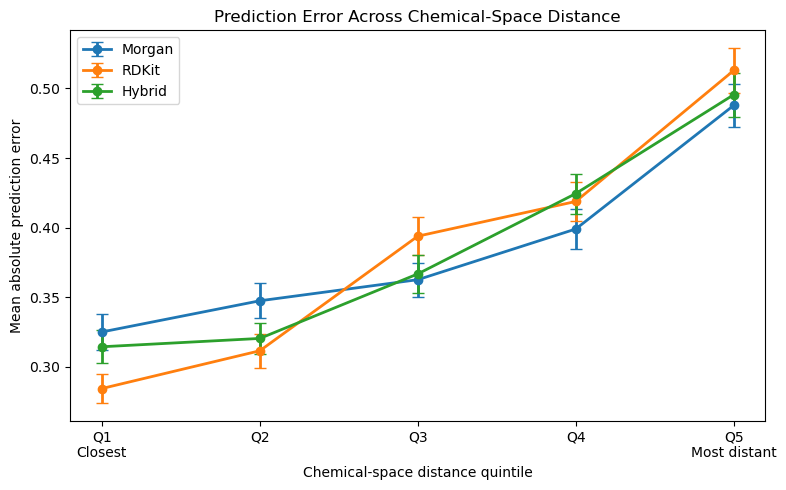

In [17]:
import matplotlib.pyplot as plt
import numpy as np

representations = {
    "Morgan": "Morgan_bin",
    "RDKit": "RDKit_bin",
    "Hybrid": "Hybrid_bin"
}

summary_data = {}

for name, bin_col in representations.items():
    summary = (
        test_analysis
        .groupby(bin_col, observed=True)["absolute_error"]
        .agg(["mean", "std", "count"])
    )

    summary["sem"] = summary["std"] / np.sqrt(summary["count"])
    summary_data[name] = summary


# Plot
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(5)

for name, summary in summary_data.items():

    means = summary["mean"].values
    sem = summary["sem"].values

    ax.errorbar(
        x,
        means,
        yerr=sem,
        marker="o",
        linewidth=2,
        capsize=4,
        label=name
    )

ax.set_xticks(x)
ax.set_xticklabels([
    "Q1\nClosest",
    "Q2",
    "Q3",
    "Q4",
    "Q5\nMost distant"
])

ax.set_xlabel("Chemical-space distance quintile")
ax.set_ylabel("Mean absolute prediction error")
ax.set_title("Prediction Error Across Chemical-Space Distance")
ax.legend()

plt.tight_layout()
plt.show()

- Across Q1 → Q5, prediction error generally increases for all three representations:
- Morgan: ~0.325 → ~0.488
- RDKit: ~0.284 → ~0.513
- Hybrid: ~0.314 → ~0.496
- The error increase is especially pronounced from Q4 → Q5, where the most chemically distant molecules show substantially higher prediction error.
- The figure also makes an important point visible:
- The relationship between chemical-space distance and prediction error depends on the molecular representation.

> RDKit starts with the lowest error in Q1 but ends with the highest error in Q5. That is a potentially important manuscript observation.

# Chemical-space distance → prediction error
-We'll fit a simple regression for each representation and quantify:

slope

R²

confidence interval

statistical significance

This will complement the Spearman correlations and the Q1/Q5 Mann–Whitney tests.

In [18]:
from scipy.stats import linregress

for distance_col in [
    "Morgan_distance",
    "RDKit_distance",
    "Hybrid_distance"
]:

    result = linregress(
        test_analysis[distance_col],
        test_analysis["absolute_error"]
    )

    print(f"\n=== {distance_col} vs Prediction Error ===")
    print(f"Slope      : {result.slope:.6f}")
    print(f"Intercept  : {result.intercept:.6f}")
    print(f"R          : {result.rvalue:.6f}")
    print(f"R²         : {result.rvalue**2:.6f}")
    print(f"p-value    : {result.pvalue:.6e}")
    print(f"Std error  : {result.stderr:.6f}")


=== Morgan_distance vs Prediction Error ===
Slope      : 0.421553
Intercept  : 0.283482
R          : 0.161276
R²         : 0.026010
p-value    : 3.091207e-25
Std error  : 0.040346

=== RDKit_distance vs Prediction Error ===
Slope      : 0.027478
Intercept  : 0.279913
R          : 0.203251
R²         : 0.041311
p-value    : 2.162945e-39
Std error  : 0.002070

=== Hybrid_distance vs Prediction Error ===
Slope      : 0.257771
Intercept  : 0.218919
R          : 0.182798
R²         : 0.033415
p-value    : 4.588806e-32
Std error  : 0.021683


# Standardized distance–error analysis

In [19]:
from scipy.stats import linregress
from sklearn.preprocessing import StandardScaler

distance_columns = [
    "Morgan_distance",
    "RDKit_distance",
    "Hybrid_distance"
]

standardized_results = []

for distance_col in distance_columns:

    # Standardize distance
    z_distance = StandardScaler().fit_transform(
        test_analysis[[distance_col]]
    ).ravel()

    # Standardized regression
    result = linregress(
        z_distance,
        test_analysis["absolute_error"]
    )

    standardized_results.append({
        "Representation": distance_col.replace("_distance", ""),
        "Standardized_slope": result.slope,
        "R": result.rvalue,
        "R2": result.rvalue ** 2,
        "p_value": result.pvalue
    })

standardized_comparison = pd.DataFrame(standardized_results)

print("=== Standardized Chemical-Space Distance vs Prediction Error ===")
print(standardized_comparison.to_string(index=False))

=== Standardized Chemical-Space Distance vs Prediction Error ===
Representation  Standardized_slope        R       R2      p_value
        Morgan            0.063082 0.161276 0.026010 3.091207e-25
         RDKit            0.079500 0.203251 0.041311 2.162945e-39
        Hybrid            0.071500 0.182798 0.033415 4.588806e-32


> Among the three molecular representations, RDKit descriptor-based chemical-space distance exhibited the strongest association with prediction error, followed by the hybrid and Morgan representations.

> We have finished the distance → prediction-error analysis for the Morgan-based baseline, including correlation, quintiles, Mann–Whitney tests, regression, and standardized slopes.

# Test the same Random Forest model across all three molecular representations:
- Morgan fingerprints
- RDKit descriptors
- Balanced hybrid representation

# Representation-specific Random Forest models

In [20]:
print("=== Representation Shapes ===")

print("Morgan :", X_morgan.shape)
print("RDKit  :", X_rdkit_scaled.shape)
print("Hybrid :", X_hybrid_balanced.shape)

print("\nTrain indices:", len(train_idx))
print("Test indices :", len(test_idx))

=== Representation Shapes ===
Morgan : (20449, 2048)


NameError: name 'X_rdkit_scaled' is not defined

In [21]:
import pickle

with open("RDKit_descriptor_chemical_space.pkl", "rb") as f:
    rdkit_data = pickle.load(f)

print("Keys:")
print(rdkit_data.keys())

Keys:
dict_keys(['molecules', 'descriptors', 'descriptors_scaled', 'descriptor_names', 'nearest_neighbor_distance'])


In [22]:
X_rdkit_scaled = rdkit_data["descriptors_scaled"]

print("RDKit scaled matrix shape:", X_rdkit_scaled.shape)
print("Data type:", X_rdkit_scaled.dtype)

RDKit scaled matrix shape: (20449, 205)
Data type: float64


In [23]:
import pickle

with open("Hybrid_chemical_space.pkl", "rb") as f:
    hybrid_data = pickle.load(f)

print("Keys:")
print(hybrid_data.keys())

Keys:
dict_keys(['molecules', 'morgan_normalized', 'rdkit_normalized', 'hybrid_representation', 'nearest_neighbor_distance', 'nearest_neighbor_index'])


In [24]:
X_hybrid_balanced = hybrid_data["hybrid_representation"]

print("Hybrid representation shape:", X_hybrid_balanced.shape)
print("Data type:", X_hybrid_balanced.dtype)

Hybrid representation shape: (20449, 2253)
Data type: float64


In [25]:
print("=== Representation Alignment Check ===")

print("Morgan molecules:", len(morgan_data["df_cs"]))
print("RDKit molecules :", len(rdkit_data["molecules"]))
print("Hybrid molecules:", len(hybrid_data["molecules"]))

print("\nFirst molecule:")
print("Morgan:", morgan_data["df_cs"]["rdkit_canonical_smiles"].iloc[0])
print("RDKit :", rdkit_data["molecules"][0])
print("Hybrid:", hybrid_data["molecules"][0])

=== Representation Alignment Check ===
Morgan molecules: 20449
RDKit molecules : 20449
Hybrid molecules: 20449

First molecule:
Morgan: Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1
RDKit : Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1
Hybrid: Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1


In [26]:
# Extract molecule identifiers
morgan_mols = morgan_data["df_cs"]["rdkit_canonical_smiles"].values
rdkit_mols = np.asarray(rdkit_data["molecules"])
hybrid_mols = np.asarray(hybrid_data["molecules"])

# Compare complete ordering
morgan_rdkit_match = np.array_equal(morgan_mols, rdkit_mols)
morgan_hybrid_match = np.array_equal(morgan_mols, hybrid_mols)
rdkit_hybrid_match = np.array_equal(rdkit_mols, hybrid_mols)

print("=== Complete Representation Alignment ===")
print("Morgan == RDKit :", morgan_rdkit_match)
print("Morgan == Hybrid:", morgan_hybrid_match)
print("RDKit == Hybrid :", rdkit_hybrid_match)

print("\nAll representations aligned:",
      morgan_rdkit_match and morgan_hybrid_match and rdkit_hybrid_match)

=== Complete Representation Alignment ===
Morgan == RDKit : True
Morgan == Hybrid: True
RDKit == Hybrid : True

All representations aligned: True


# Create the three train/Test datasets:

In [27]:
# ============================================
# Representation-specific train/test datasets
# ============================================

X_morgan_train = X_morgan[train_idx]
X_morgan_test  = X_morgan[test_idx]

X_rdkit_train = X_rdkit_scaled[train_idx]
X_rdkit_test  = X_rdkit_scaled[test_idx]

X_hybrid_train = X_hybrid_balanced[train_idx]
X_hybrid_test  = X_hybrid_balanced[test_idx]

print("=== Train/Test Shapes ===")

print("Morgan train:", X_morgan_train.shape)
print("Morgan test :", X_morgan_test.shape)

print("RDKit train :", X_rdkit_train.shape)
print("RDKit test  :", X_rdkit_test.shape)

print("Hybrid train:", X_hybrid_train.shape)
print("Hybrid test :", X_hybrid_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

=== Train/Test Shapes ===
Morgan train: (16359, 2048)
Morgan test : (4090, 2048)
RDKit train : (16359, 205)
RDKit test  : (4090, 205)
Hybrid train: (16359, 2253)
Hybrid test : (4090, 2253)
y_train: (16359,)
y_test : (4090,)


# Train the Three RF Models

In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    return mae, rmse, r2


# ============================================
# Morgan RF
# ============================================

rf_morgan = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_morgan.fit(X_morgan_train, y_train)
pred_morgan = rf_morgan.predict(X_morgan_test)

mae_morgan, rmse_morgan, r2_morgan = calculate_metrics(
    y_test, pred_morgan
)

print("Morgan RF completed.")


# ============================================
# RDKit RF
# ============================================

rf_rdkit = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_rdkit.fit(X_rdkit_train, y_train)
pred_rdkit = rf_rdkit.predict(X_rdkit_test)

mae_rdkit, rmse_rdkit, r2_rdkit = calculate_metrics(
    y_test, pred_rdkit
)

print("RDKit RF completed.")


# ============================================
# Hybrid RF
# ============================================

rf_hybrid = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_hybrid.fit(X_hybrid_train, y_train)
pred_hybrid = rf_hybrid.predict(X_hybrid_test)

mae_hybrid, rmse_hybrid, r2_hybrid = calculate_metrics(
    y_test, pred_hybrid
)

print("Hybrid RF completed.")

Morgan RF completed.
RDKit RF completed.
Hybrid RF completed.


In [29]:
print("=== Representation-Specific Random Forest Performance ===")

print(f"\nMorgan")
print(f"MAE  : {mae_morgan:.4f}")
print(f"RMSE : {rmse_morgan:.4f}")
print(f"R²   : {r2_morgan:.4f}")

print(f"\nRDKit")
print(f"MAE  : {mae_rdkit:.4f}")
print(f"RMSE : {rmse_rdkit:.4f}")
print(f"R²   : {r2_rdkit:.4f}")

print(f"\nHybrid")
print(f"MAE  : {mae_hybrid:.4f}")
print(f"RMSE : {rmse_hybrid:.4f}")
print(f"R²   : {r2_hybrid:.4f}")

=== Representation-Specific Random Forest Performance ===

Morgan
MAE  : 0.3842
RMSE : 0.5483
R²   : 0.5571

RDKit
MAE  : 0.4037
RMSE : 0.5670
R²   : 0.5263

Hybrid
MAE  : 0.3974
RMSE : 0.5584
R²   : 0.5405


# Save these predictions
Before doing anything else, let's create a single table containing predictions and errors from all three models.

In [30]:
representation_predictions = chemical_space_master.iloc[test_idx].copy()

representation_predictions["y_true"] = y_test

representation_predictions["Morgan_pred"] = pred_morgan
representation_predictions["RDKit_pred"] = pred_rdkit
representation_predictions["Hybrid_pred"] = pred_hybrid

representation_predictions["Morgan_error"] = np.abs(
    y_test - pred_morgan
)

representation_predictions["RDKit_error"] = np.abs(
    y_test - pred_rdkit
)

representation_predictions["Hybrid_error"] = np.abs(
    y_test - pred_hybrid
)

print("=== Representation Prediction Dataset ===")
print("Rows:", len(representation_predictions))
print("Columns:", len(representation_predictions.columns))

print("\nColumns:")
print(representation_predictions.columns.tolist())

print("\nMissing values:")
print(representation_predictions.isna().sum())

=== Representation Prediction Dataset ===
Rows: 4090
Columns: 12

Columns:
['canonical_smiles', 'log10_median_papp', 'Morgan_distance', 'RDKit_distance', 'Hybrid_distance', 'y_true', 'Morgan_pred', 'RDKit_pred', 'Hybrid_pred', 'Morgan_error', 'RDKit_error', 'Hybrid_error']

Missing values:
canonical_smiles     0
log10_median_papp    0
Morgan_distance      0
RDKit_distance       0
Hybrid_distance      0
y_true               0
Morgan_pred          0
RDKit_pred           0
Hybrid_pred          0
Morgan_error         0
RDKit_error          0
Hybrid_error         0
dtype: int64


# Representation-specific Spearman correlations

In [31]:
from scipy.stats import spearmanr

representation_pairs = {
    "Morgan": ("Morgan_distance", "Morgan_error"),
    "RDKit": ("RDKit_distance", "RDKit_error"),
    "Hybrid": ("Hybrid_distance", "Hybrid_error")
}

results = []

for representation, (distance_col, error_col) in representation_pairs.items():

    rho, p_value = spearmanr(
        representation_predictions[distance_col],
        representation_predictions[error_col]
    )

    results.append({
        "Representation": representation,
        "Spearman_rho": rho,
        "p_value": p_value
    })

representation_distance_error = pd.DataFrame(results)

print("=== Representation-Specific Distance–Error Correlation ===")
print(representation_distance_error.to_string(index=False))

=== Representation-Specific Distance–Error Correlation ===
Representation  Spearman_rho      p_value
        Morgan      0.177002 3.877930e-30
         RDKit      0.250541 1.407923e-59
        Hybrid      0.188698 4.295097e-34


In [32]:
# ============================================
# Representation-specific distance bins
# ============================================

for distance_col in [
    "Morgan_distance",
    "RDKit_distance",
    "Hybrid_distance"
]:

    bin_col = distance_col.replace("_distance", "_model_bin")

    representation_predictions[bin_col] = pd.qcut(
        representation_predictions[distance_col],
        q=5,
        labels=[
            "Q1 (closest)",
            "Q2",
            "Q3",
            "Q4",
            "Q5 (most distant)"
        ],
        duplicates="drop"
    )


# ============================================
# Matching distance → model-error analysis
# ============================================

representation_pairs = {
    "Morgan": ("Morgan_model_bin", "Morgan_error"),
    "RDKit": ("RDKit_model_bin", "RDKit_error"),
    "Hybrid": ("Hybrid_model_bin", "Hybrid_error")
}

for name, (bin_col, error_col) in representation_pairs.items():

    print(f"\n=== {name}: Distance vs Model Error ===")

    summary = (
        representation_predictions
        .groupby(bin_col, observed=True)[error_col]
        .agg(["count", "mean", "median", "std"])
    )

    print(summary)


=== Morgan: Distance vs Model Error ===
                   count      mean    median       std
Morgan_model_bin                                      
Q1 (closest)         823  0.324902  0.203168  0.364031
Q2                   826  0.347329  0.243267  0.358989
Q3                   806  0.362498  0.254542  0.347823
Q4                   817  0.398945  0.289953  0.413284
Q5 (most distant)    818  0.487839  0.378185  0.443041

=== RDKit: Distance vs Model Error ===
                   count      mean    median       std
RDKit_model_bin                                       
Q1 (closest)         818  0.296447  0.209219  0.287392
Q2                   818  0.311241  0.213627  0.335361
Q3                   818  0.395222  0.286577  0.378358
Q4                   818  0.480391  0.374486  0.441125
Q5 (most distant)    818  0.535137  0.424875  0.466302

=== Hybrid: Distance vs Model Error ===
                   count      mean    median       std
Hybrid_model_bin                                     

# Test the Q1 vs Q5 differences using the matching model errors

In [33]:
from scipy.stats import mannwhitneyu

representation_pairs = {
    "Morgan": ("Morgan_model_bin", "Morgan_error"),
    "RDKit": ("RDKit_model_bin", "RDKit_error"),
    "Hybrid": ("Hybrid_model_bin", "Hybrid_error")
}

for name, (bin_col, error_col) in representation_pairs.items():

    q1 = representation_predictions.loc[
        representation_predictions[bin_col] == "Q1 (closest)",
        error_col
    ]

    q5 = representation_predictions.loc[
        representation_predictions[bin_col] == "Q5 (most distant)",
        error_col
    ]

    U, p_value = mannwhitneyu(
        q1,
        q5,
        alternative="two-sided"
    )

    rank_biserial = 1 - (2 * U) / (len(q1) * len(q5))

    print(f"\n=== {name}: Q1 vs Q5 ===")
    print(f"Q1 mean error: {q1.mean():.4f}")
    print(f"Q5 mean error: {q5.mean():.4f}")
    print(f"Mann-Whitney U: {U:.2f}")
    print(f"p-value: {p_value:.6e}")
    print(f"Rank-biserial effect size: {rank_biserial:.4f}")


=== Morgan: Q1 vs Q5 ===
Q1 mean error: 0.3249
Q5 mean error: 0.4878
Mann-Whitney U: 239788.00
p-value: 6.271338e-24
Rank-biserial effect size: 0.2876

=== RDKit: Q1 vs Q5 ===
Q1 mean error: 0.2964
Q5 mean error: 0.5351
Mann-Whitney U: 215829.00
p-value: 1.854186e-35
Rank-biserial effect size: 0.3549

=== Hybrid: Q1 vs Q5 ===
Q1 mean error: 0.3180
Q5 mean error: 0.5014
Mann-Whitney U: 242895.00
p-value: 8.430179e-22
Rank-biserial effect size: 0.2740


# The prediction errors of Morgan, RDKit, and Hybrid are significantly different on the exact same 4,090 molecules.

# Overall paired comparison
First, let's calculate the error distributions:

In [34]:
from scipy.stats import friedmanchisquare

# Same 4090 molecules evaluated by all three models
morgan_errors = representation_predictions["Morgan_error"]
rdkit_errors = representation_predictions["RDKit_error"]
hybrid_errors = representation_predictions["Hybrid_error"]

# Friedman test: overall paired comparison
statistic, p_value = friedmanchisquare(
    morgan_errors,
    rdkit_errors,
    hybrid_errors
)

print("=== Friedman Test: Model Error Comparison ===")
print(f"Statistic: {statistic:.4f}")
print(f"p-value : {p_value:.6e}")

=== Friedman Test: Model Error Comparison ===
Statistic: 30.5485
p-value : 2.325279e-07


# Paired pairwise tests
We'll compare the same 4,090 molecules pairwise using the Wilcoxon signed-rank test:
- Morgan vs RDKit
- Morgan vs Hybrid
- RDKit vs Hybrid
- 
We'll use Holm correction for the three comparisons.

In [36]:
from scipy.stats import wilcoxon

pairs = {
    "Morgan vs RDKit": (
        morgan_errors,
        rdkit_errors
    ),
    "Morgan vs Hybrid": (
        morgan_errors,
        hybrid_errors
    ),
    "RDKit vs Hybrid": (
        rdkit_errors,
        hybrid_errors
    )
}

pairwise_results = []

for name, (errors_a, errors_b) in pairs.items():

    statistic, p_value = wilcoxon(
        errors_a,
        errors_b,
        alternative="two-sided"
    )

    pairwise_results.append({
        "Comparison": name,
        "Wilcoxon_statistic": statistic,
        "raw_p": p_value
    })


pairwise_results = pd.DataFrame(pairwise_results)


# ============================================
# Holm multiple-comparison correction
# ============================================

pairwise_results = pairwise_results.sort_values(
    "raw_p"
).reset_index(drop=True)

m = len(pairwise_results)

pairwise_results["Holm_p"] = [
    min((m - i) * p, 1.0)
    for i, p in enumerate(pairwise_results["raw_p"])
]

# Ensure corrected p-values are monotonic
for i in range(1, m):
    pairwise_results.loc[i, "Holm_p"] = max(
        pairwise_results.loc[i, "Holm_p"],
        pairwise_results.loc[i-1, "Holm_p"]
    )

pairwise_results["Significant"] = (
    pairwise_results["Holm_p"] < 0.05
)

print("=== Pairwise Wilcoxon Tests ===")
print(pairwise_results.to_string(index=False))

=== Pairwise Wilcoxon Tests ===
      Comparison  Wilcoxon_statistic    raw_p   Holm_p  Significant
 Morgan vs RDKit           3833683.5 0.000004 0.000011         True
Morgan vs Hybrid           3922944.0 0.000573 0.001146         True
 RDKit vs Hybrid           3952607.0 0.002946 0.002946         True


# Paired effect sizes for:
- Morgan vs RDKit
- Morgan vs Hybrid
- RDKit vs Hybrid

We'll use a paired rank-based effect size consistent with the Wilcoxon analysis.

In [38]:
# ============================================
# Paired effect size: rank-biserial correlation
# ============================================

def wilcoxon_rank_biserial(x, y):
    
    differences = np.asarray(x) - np.asarray(y)
    
    # Remove exact ties
    differences = differences[differences != 0]
    
    ranks = np.abs(differences)
    
    # Rank absolute differences
    from scipy.stats import rankdata
    ranks = rankdata(ranks)
    
    positive_rank_sum = ranks[differences > 0].sum()
    negative_rank_sum = ranks[differences < 0].sum()
    
    total_rank = positive_rank_sum + negative_rank_sum
    
    return (positive_rank_sum - negative_rank_sum) / total_rank


effect_results = []

for name, (errors_a, errors_b) in pairs.items():

    effect = wilcoxon_rank_biserial(
        errors_a,
        errors_b
    )

    effect_results.append({
        "Comparison": name,
        "Rank_biserial_effect": effect
    })

effect_results = pd.DataFrame(effect_results)

print("=== Paired Effect Sizes ===")
print(effect_results.to_string(index=False))

=== Paired Effect Sizes ===
      Comparison  Rank_biserial_effect
 Morgan vs RDKit             -0.083519
Morgan vs Hybrid             -0.062180
 RDKit vs Hybrid              0.053702


# Does the distance–error relationship remain after removing extreme chemical-space outliers?

Remove the top 1% most distant molecules separately for each representation, then recalculate the Spearman distance–error relationship using the matching model errors.

In [39]:
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

representation_pairs = {
    "Morgan": ("Morgan_distance", "Morgan_error"),
    "RDKit": ("RDKit_distance", "RDKit_error"),
    "Hybrid": ("Hybrid_distance", "Hybrid_error")
}

robustness_results = []

for name, (distance_col, error_col) in representation_pairs.items():

    data = representation_predictions[
        [distance_col, error_col]
    ].dropna()

    # 99th percentile cutoff
    cutoff = data[distance_col].quantile(0.99)

    # Remove top 1% most distant molecules
    filtered = data[data[distance_col] <= cutoff]

    rho, p_value = spearmanr(
        filtered[distance_col],
        filtered[error_col]
    )

    robustness_results.append({
        "Representation": name,
        "Original_N": len(data),
        "Filtered_N": len(filtered),
        "Distance_cutoff_99th_percentile": cutoff,
        "Spearman_rho": rho,
        "p_value": p_value
    })

robustness_results = pd.DataFrame(robustness_results)

print("=== Robustness Analysis: Excluding Top 1% Distance Outliers ===")
print(robustness_results.to_string(index=False))

=== Robustness Analysis: Excluding Top 1% Distance Outliers ===
Representation  Original_N  Filtered_N  Distance_cutoff_99th_percentile  Spearman_rho      p_value
        Morgan        4090        4049                         0.703434      0.171821 3.348763e-28
         RDKit        4090        4049                        11.491506      0.244664 2.901296e-56
        Hybrid        4090        4049                         1.361083      0.187652 2.083724e-33


# Does molecular representation significantly alter the sensitivity of prediction error to chemical-space distance?

# Bootstrap comparison of standardized slopes

We'll standardize each distance first, then repeatedly resample the same molecules and calculate differences between the regression slopes.

In [40]:
import numpy as np
import pandas as pd

# ============================================
# Prepare standardized distances
# ============================================

data = representation_predictions.copy()

distance_columns = [
    "Morgan_distance",
    "RDKit_distance",
    "Hybrid_distance"
]

error_columns = [
    "Morgan_error",
    "RDKit_error",
    "Hybrid_error"
]

Z = {}

for distance_col in distance_columns:
    
    mean = data[distance_col].mean()
    std = data[distance_col].std()
    
    Z[distance_col] = (
        (data[distance_col] - mean) / std
    ).values


errors = {
    "Morgan": data["Morgan_error"].values,
    "RDKit": data["RDKit_error"].values,
    "Hybrid": data["Hybrid_error"].values
}


# ============================================
# Observed standardized slopes
# ============================================

def standardized_slope(x, y):
    return np.polyfit(x, y, 1)[0]


observed_slopes = {
    "Morgan": standardized_slope(
        Z["Morgan_distance"],
        errors["Morgan"]
    ),
    
    "RDKit": standardized_slope(
        Z["RDKit_distance"],
        errors["RDKit"]
    ),
    
    "Hybrid": standardized_slope(
        Z["Hybrid_distance"],
        errors["Hybrid"]
    )
}

print("=== Observed Standardized Slopes ===")

for name, slope in observed_slopes.items():
    print(f"{name}: {slope:.6f}")

=== Observed Standardized Slopes ===
Morgan: 0.063090
RDKit: 0.085409
Hybrid: 0.069732


In [41]:
# ============================================
# Paired bootstrap
# ============================================

rng = np.random.default_rng(42)

n = len(data)
n_bootstrap = 5000

bootstrap_differences = {
    "RDKit - Morgan": [],
    "RDKit - Hybrid": [],
    "Hybrid - Morgan": []
}

for _ in range(n_bootstrap):

    # Same resampled molecules for every representation
    indices = rng.integers(
        0,
        n,
        size=n
    )

    slopes = {}

    for name, distance_col, error_name in [
        ("Morgan", "Morgan_distance", "Morgan"),
        ("RDKit", "RDKit_distance", "RDKit"),
        ("Hybrid", "Hybrid_distance", "Hybrid")
    ]:
        
        x = Z[distance_col][indices]
        y = errors[error_name][indices]
        
        slopes[name] = standardized_slope(x, y)

    bootstrap_differences["RDKit - Morgan"].append(
        slopes["RDKit"] - slopes["Morgan"]
    )

    bootstrap_differences["RDKit - Hybrid"].append(
        slopes["RDKit"] - slopes["Hybrid"]
    )

    bootstrap_differences["Hybrid - Morgan"].append(
        slopes["Hybrid"] - slopes["Morgan"]
    )


# ============================================
# Bootstrap confidence intervals
# ============================================

print("\n=== Bootstrap Comparison of Standardized Slopes ===")

for comparison, values in bootstrap_differences.items():

    values = np.asarray(values)

    observed_difference = values.mean()

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)

    print(f"\n{comparison}")
    print(f"Mean bootstrap difference: {observed_difference:.6f}")
    print(f"95% CI: [{lower:.6f}, {upper:.6f}]")


=== Bootstrap Comparison of Standardized Slopes ===

RDKit - Morgan
Mean bootstrap difference: 0.024562
95% CI: [0.002388, 0.048211]

RDKit - Hybrid
Mean bootstrap difference: 0.017904
95% CI: [-0.003450, 0.039174]

Hybrid - Morgan
Mean bootstrap difference: 0.006657
95% CI: [-0.002334, 0.015674]


In [42]:
# ============================================
# SAVE PRIMARY RESEARCH RESULTS
# ============================================

import pickle
import pandas as pd

primary_results = {

    # Dataset
    "n_molecules": 20449,
    "n_test_molecules": 4090,

    # Representation dimensions
    "Morgan_features": 2048,
    "RDKit_features": 205,
    "Hybrid_features": 2253,

    # Random Forest performance
    "model_performance": {
        "Morgan": {
            "MAE": 0.3842,
            "RMSE": 0.5483,
            "R2": 0.5571
        },
        "RDKit": {
            "MAE": 0.4037,
            "RMSE": 0.5670,
            "R2": 0.5263
        },
        "Hybrid": {
            "MAE": 0.3974,
            "RMSE": 0.5584,
            "R2": 0.5405
        }
    },

    # Representation-specific Spearman correlations
    "distance_error_spearman": {
        "Morgan": {
            "rho": 0.177002,
            "p": 3.877930e-30
        },
        "RDKit": {
            "rho": 0.250541,
            "p": 1.407923e-59
        },
        "Hybrid": {
            "rho": 0.188698,
            "p": 4.295097e-34
        }
    },

    # Q1 vs Q5
    "q1_q5": {
        "Morgan": {
            "Q1_mean_error": 0.3249,
            "Q5_mean_error": 0.4878,
            "increase_percent": 50.1,
            "rank_biserial": 0.2876,
            "p": 6.271338e-24
        },
        "RDKit": {
            "Q1_mean_error": 0.2964,
            "Q5_mean_error": 0.5351,
            "increase_percent": 80.6,
            "rank_biserial": 0.3549,
            "p": 1.854186e-35
        },
        "Hybrid": {
            "Q1_mean_error": 0.3180,
            "Q5_mean_error": 0.5014,
            "increase_percent": 57.7,
            "rank_biserial": 0.2740,
            "p": 8.430179e-22
        }
    },

    # Overall paired comparison
    "friedman_test": {
        "statistic": 30.5485,
        "p": 2.325279e-07
    },

    # Pairwise model-error comparison
    "pairwise_wilcoxon": {
        "Morgan_vs_RDKit": {
            "raw_p": 0.000004,
            "Holm_p": 0.000011,
            "effect": -0.083519
        },
        "Morgan_vs_Hybrid": {
            "raw_p": 0.000573,
            "Holm_p": 0.001146,
            "effect": -0.062180
        },
        "RDKit_vs_Hybrid": {
            "raw_p": 0.002946,
            "Holm_p": 0.002946,
            "effect": 0.053702
        }
    },

    # Standardized slopes
    "standardized_slopes": {
        "Morgan": 0.063090,
        "RDKit": 0.085409,
        "Hybrid": 0.069732
    },

    # Bootstrap slope comparisons
    "bootstrap_slope_comparison": {
        "RDKit_vs_Morgan": {
            "difference": 0.024562,
            "CI95": [0.002388, 0.048211]
        },
        "RDKit_vs_Hybrid": {
            "difference": 0.017904,
            "CI95": [-0.003450, 0.039174]
        },
        "Hybrid_vs_Morgan": {
            "difference": 0.006657,
            "CI95": [-0.002334, 0.015674]
        }
    },

    # Robustness analysis
    "outlier_robustness": {
        "Morgan": {
            "original_rho": 0.177002,
            "robust_rho": 0.171821
        },
        "RDKit": {
            "original_rho": 0.250541,
            "robust_rho": 0.244664
        },
        "Hybrid": {
            "original_rho": 0.188698,
            "robust_rho": 0.187652
        }
    }
}


# Save results
with open("Caco2_chemical_space_primary_results.pkl", "wb") as f:
    pickle.dump(primary_results, f)

print("Primary research results saved successfully.")

Primary research results saved successfully.


# 06 — Baseline Prediction Model and Representation-Dependent Chemical-Space Analysis

## 1. Notebook Objective

This notebook evaluates whether the relationship between chemical-space distance and prediction error depends on the molecular representation used to describe the molecules.

The analysis uses three molecular representations:

1. Morgan fingerprints
2. RDKit molecular descriptors
3. Hybrid representation combining normalized Morgan and RDKit representations

A Random Forest regression model is trained separately using each representation to predict the experimental Caco-2 permeability target.

The central analysis then asks:

> Does prediction error increase as a test molecule becomes more distant from its local chemical neighborhood, and does the strength of this relationship depend on molecular representation?

The notebook therefore separates two related questions:

- Predictive performance: Which representation gives the best overall prediction?
- Chemical-space dependence: How strongly does prediction error change with chemical-space distance?

This distinction is important because a representation can provide good overall prediction performance while showing a different sensitivity to chemical-space distance.

---

# 2. Dataset Used

The analysis is based on the curated Caco-2 permeability dataset generated in the preceding notebooks.

The final chemical-space master dataset contains:

- 20,449 molecules
- 5 columns

The master table contains:

- canonical_smiles
- log10_median_papp
- Morgan_distance
- RDKit_distance
- Hybrid_distance

All five columns contain complete data.

### Dataset completeness

- Missing canonical SMILES: 0
- Missing target values: 0
- Missing Morgan distances: 0
- Missing RDKit distances: 0
- Missing Hybrid distances: 0

Thus, all 20,449 molecules are available for the subsequent analysis.

---

# 3. Prediction Target

The prediction target is:

log10_median_papp

where the experimental Caco-2 permeability measurements have been represented on a logarithmic scale.

### Target quality check

Number of molecules:

20,449

Missing values:

0

Infinite values:

0

### Target distribution

| Statistic | Value |
|---|---:|
| Count | 20,449 |
| Mean | 0.852952 |
| Standard deviation | 0.820542 |
| Minimum | -4.000000 |
| 25th percentile | 0.380211 |
| Median | 0.982271 |
| 75th percentile | 1.361728 |
| Maximum | 4.444661 |

The complete target distribution is therefore available for model training, testing, and prediction-error analysis.

---

# 4. Molecular Representations

Three molecular representations are evaluated.

## 4.1 Morgan Fingerprint Representation

Each molecule is represented using a 2,048-dimensional Morgan fingerprint.

Shape:

(20449, 2048)

The Morgan representation is used as the structural/fingerprint-based representation of molecular chemical space.

The corresponding chemical-space distance is stored as:

Morgan_distance

---

## 4.2 RDKit Descriptor Representation

Each molecule is represented using 205 RDKit molecular descriptors.

Before chemical-space analysis, the descriptor matrix is scaled.

Shape:

(20449, 205)

Data type:

float64

The scaled descriptor representation is used to construct the RDKit-based chemical space.

The corresponding distance is stored as:

RDKit_distance

---

## 4.3 Hybrid Representation

The Hybrid representation combines:

- 2,048 Morgan features
- 205 RDKit descriptors

Total:

2,253 features

Shape:

(20449, 2253)

The Morgan and RDKit components were normalized before combination so that one representation did not dominate the combined feature space simply because of its numerical magnitude.

The resulting Hybrid representation is stored as:

X_hybrid_balanced

The corresponding chemical-space distance is stored as:

Hybrid_distance

---

# 5. Representation Alignment

Before model comparison, the molecular ordering of all three representations was explicitly checked.

Number of molecules:

- Morgan: 20,449
- RDKit: 20,449
- Hybrid: 20,449

The first molecule was identical across all three representations.

A complete equality check showed:

- Morgan == RDKit: True
- Morgan == Hybrid: True
- RDKit == Hybrid: True

Therefore:

> All three molecular representations are aligned to the same molecular order.

This is essential because representation-specific predictions and errors must correspond to the same molecules.

---

# 6. Train/Test Split

The same train/test indices are used for all three representations.

Total molecules:

20,449

Training set:

16,359 molecules

Test set:

4,090 molecules

The resulting matrices are:

### Morgan

Training:

(16359, 2048)

Testing:

(4090, 2048)

### RDKit

Training:

(16359, 205)

Testing:

(4090, 205)

### Hybrid

Training:

(16359, 2253)

Testing:

(4090, 2253)

Target vectors:

Training:

(16359,)

Testing:

(4090,)

Using identical train/test indices is critical for a fair representation-level comparison because every representation is evaluated on exactly the same molecules.

---

# 7. Baseline Prediction Model

A Random Forest Regressor is used as the baseline prediction model.

The same model configuration is applied to each representation:

- Number of trees: 500
- Random state: 42
- Parallel processing: enabled using all available CPU cores

The model is trained independently on:

1. Morgan features
2. RDKit descriptors
3. Hybrid features

No representation is given a different model architecture or training/test split.

This allows differences in performance to be interpreted primarily in relation to the molecular representation.

---

# 8. Baseline Prediction Performance

The Random Forest models were evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of determination (R²)

### Morgan

- MAE: 0.3842
- RMSE: 0.5483
- R²: 0.5571

### RDKit

- MAE: 0.4037
- RMSE: 0.5670
- R²: 0.5263

### Hybrid

- MAE: 0.3974
- RMSE: 0.5584
- R²: 0.5405

Among the three representations, Morgan produced the lowest MAE and RMSE and the highest R² in this baseline experiment.

Therefore, Morgan provided the strongest overall predictive performance under the present Random Forest configuration.

---

# 9. Prediction Error

For every test molecule, the absolute prediction error was calculated as:

Absolute error = |experimental value − predicted value|

The test set contains:

4,090 molecules

For the Morgan baseline:

- Mean absolute error: 0.3842179
- Median absolute error: 0.2680054
- Minimum error: approximately 0
- Maximum error: 4.2372974

Representation-specific prediction datasets were then constructed containing:

- canonical SMILES
- experimental target
- Morgan distance
- RDKit distance
- Hybrid distance
- true target
- Morgan prediction
- RDKit prediction
- Hybrid prediction
- Morgan error
- RDKit error
- Hybrid error

The resulting analysis dataset contains:

4,090 rows × 12 columns

No missing values were present.

---

# 10. Chemical-Space Distance

For each molecular representation, a chemical-space distance was calculated to characterize how far a molecule lies from its local chemical neighborhood.

The resulting master table contains:

- Morgan_distance
- RDKit_distance
- Hybrid_distance

These distances are then linked to the prediction error of the corresponding test molecule.

The key analytical variable is therefore:

> Chemical-space distance → prediction error

The purpose is not simply to determine whether the model predicts accurately on average, but to determine whether prediction reliability changes as molecules become more chemically distant from their local neighborhood.

---

# 11. Representation-Specific Distance–Error Correlation

Spearman rank correlation was used to quantify the monotonic relationship between chemical-space distance and prediction error.

### Results

| Representation | Spearman ρ | p-value |
|---|---:|---:|
| Morgan | 0.177002 | 3.88 × 10⁻³⁰ |
| RDKit | 0.250541 | 1.41 × 10⁻⁵⁹ |
| Hybrid | 0.188698 | 4.30 × 10⁻³⁴ |

All three representations show a positive association between chemical-space distance and prediction error.

The strongest association was observed for the RDKit representation.

The observed ordering was:

RDKit > Hybrid > Morgan

in terms of Spearman distance–error correlation.

---

# 12. Chemical-Space Quintile Analysis

To examine the relationship more directly, test molecules were divided into five distance groups:

- Q1: closest molecules
- Q2
- Q3
- Q4
- Q5: most distant molecules

Prediction error was then summarized within each distance quintile.

This analysis provides an interpretable view of how model error changes across increasing chemical-space distance.

---

## 12.1 Morgan

| Quintile | n | Mean error | Median error | SD |
|---|---:|---:|---:|---:|
| Q1 | 823 | 0.3249 | 0.2032 | 0.3640 |
| Q2 | 826 | 0.3473 | 0.2433 | 0.3590 |
| Q3 | 806 | 0.3625 | 0.2545 | 0.3478 |
| Q4 | 817 | 0.3989 | 0.2900 | 0.4133 |
| Q5 | 818 | 0.4878 | 0.3782 | 0.4430 |

Morgan prediction error increases progressively toward the most distant chemical-space quintile.

---

## 12.2 RDKit

| Quintile | n | Mean error | Median error | SD |
|---|---:|---:|---:|---:|
| Q1 | 818 | 0.2964 | 0.2092 | 0.2874 |
| Q2 | 818 | 0.3112 | 0.2136 | 0.3354 |
| Q3 | 818 | 0.3952 | 0.2866 | 0.3784 |
| Q4 | 818 | 0.4804 | 0.3745 | 0.4411 |
| Q5 | 818 | 0.5351 | 0.4249 | 0.4663 |

RDKit shows a particularly pronounced increase in error across the chemical-space quintiles.

---

## 12.3 Hybrid

| Quintile | n | Mean error | Median error | SD |
|---|---:|---:|---:|---:|
| Q1 | 818 | 0.3180 | 0.2060 | 0.3165 |
| Q2 | 818 | 0.3354 | 0.2393 | 0.3279 |
| Q3 | 818 | 0.3826 | 0.2767 | 0.3773 |
| Q4 | 818 | 0.4497 | 0.3464 | 0.4291 |
| Q5 | 818 | 0.5014 | 0.3664 | 0.4608 |

The Hybrid representation also shows increasing prediction error with increasing chemical-space distance.

---

# 13. Q1 versus Q5 Statistical Comparison

To formally compare the closest and most distant chemical-space groups, Q1 and Q5 prediction errors were compared.

### Morgan

- Q1 mean error: 0.3249
- Q5 mean error: 0.4878
- Mann–Whitney U: 239,788
- p-value: 6.27 × 10⁻²⁴
- Rank-biserial effect size: 0.2876

### RDKit

- Q1 mean error: 0.2964
- Q5 mean error: 0.5351
- Mann–Whitney U: 215,829
- p-value: 1.85 × 10⁻³⁵
- Rank-biserial effect size: 0.3549

### Hybrid

- Q1 mean error: 0.3180
- Q5 mean error: 0.5014
- Mann–Whitney U: 242,895
- p-value: 8.43 × 10⁻²²
- Rank-biserial effect size: 0.2740

All three representations therefore show a statistically significant difference between the closest and most distant chemical-space groups.

The largest Q1-to-Q5 difference was observed for RDKit.

---

# 14. Regression Analysis

Linear regression was used as an additional characterization of the distance–error relationship.

The initial slopes were:

### Morgan

- Slope: 0.421553
- Intercept: 0.283482
- R: 0.161276
- R²: 0.026010
- p-value: 3.09 × 10⁻²⁵

### RDKit

- Slope: 0.027478
- Intercept: 0.279913
- R: 0.203251
- R²: 0.041311
- p-value: 2.16 × 10⁻³⁹

### Hybrid

- Slope: 0.257771
- Intercept: 0.218919
- R: 0.182798
- R²: 0.033415
- p-value: 4.59 × 10⁻³²

Because the numerical scales of the three distance measures differ substantially, raw slopes are not directly comparable between representations.

Therefore, standardized slopes were subsequently calculated.

---

# 15. Standardized Distance–Error Slopes

The standardized slopes were:

| Representation | Standardized slope |
|---|---:|
| Morgan | 0.063090 |
| RDKit | 0.085409 |
| Hybrid | 0.069732 |

The standardized slopes provide a scale-independent comparison of the strength of the distance–error relationship.

RDKit showed the largest standardized slope.

---

# 16. Bootstrap Comparison of Standardized Slopes

A paired bootstrap analysis was performed to directly compare standardized slopes between representations.

### RDKit versus Morgan

Mean bootstrap difference:

0.024562

95% confidence interval:

0.002388 to 0.048211

The confidence interval does not include zero, supporting a difference between the standardized RDKit and Morgan slopes.

### RDKit versus Hybrid

Mean bootstrap difference:

0.017904

95% confidence interval:

−0.003450 to 0.039174

The confidence interval includes zero; therefore, the difference is not statistically conclusive.

### Hybrid versus Morgan

Mean bootstrap difference:

0.006657

95% confidence interval:

−0.002334 to 0.015674

The confidence interval includes zero; therefore, the difference is not statistically conclusive.

### Interpretation

The bootstrap analysis provides evidence that the RDKit distance–error relationship is steeper than the Morgan relationship after standardization.

However, the available bootstrap results do not provide conclusive evidence that RDKit differs from Hybrid or that Hybrid differs from Morgan.

---

# 17. Overall Model-Error Comparison

Because each test molecule receives predictions from all three models, the prediction errors are paired across representations.

A Friedman test was therefore used to assess whether the three representations produced systematically different prediction-error distributions.

Results:

- Friedman statistic: 30.5485
- p-value: 2.33 × 10⁻⁷

The result indicates that the prediction-error distributions are not identical across the three representations.

---

# 18. Pairwise Model Comparisons

Pairwise Wilcoxon signed-rank tests were performed following the overall Friedman test.

Holm correction was applied for multiple comparisons.

### Morgan vs RDKit

- Raw p-value: 0.000004
- Holm-adjusted p-value: 0.000011
- Rank-biserial effect: −0.083519

### Morgan vs Hybrid

- Raw p-value: 0.000573
- Holm-adjusted p-value: 0.001146
- Rank-biserial effect: −0.062180

### RDKit vs Hybrid

- Raw p-value: 0.002946
- Holm-adjusted p-value: 0.002946
- Rank-biserial effect: 0.053702

All three pairwise comparisons remained statistically significant after Holm correction.

The effect sizes are relatively modest, indicating that statistical significance should not be interpreted as evidence of large practical differences in overall prediction error.

---

# 19. Robustness Analysis

A robustness analysis was performed to determine whether the observed distance–error relationships were driven primarily by the most extreme distance values.

For each representation, the top 1% of test-set distance values were excluded.

The remaining dataset contained:

4,049 molecules

compared with:

4,090 molecules originally

The distance–error correlations were then recalculated.

### Morgan

Original Spearman ρ:

0.177002

After removing the top 1%:

0.171821

p-value:

3.35 × 10⁻²⁸

### RDKit

Original Spearman ρ:

0.250541

After removing the top 1%:

0.244664

p-value:

2.90 × 10⁻⁵⁶

### Hybrid

Original Spearman ρ:

0.188698

After removing the top 1%:

0.187652

p-value:

2.08 × 10⁻³³

The correlations remain positive and statistically significant after exclusion of the most distant 1% of molecules.

This indicates that the observed distance–error relationship is not dependent solely on the most extreme distance outliers.

---

# 20. Central Findings of the Notebook

The analysis provides several complementary observations.

### Finding 1 — Overall predictive performance differs by representation

Morgan produced the strongest baseline predictive performance:

- Lowest MAE
- Lowest RMSE
- Highest R²

under the Random Forest configuration used in this notebook.

---

### Finding 2 — Prediction error increases with chemical-space distance

All three representations showed positive distance–error associations.

Therefore, molecules located farther from their local chemical neighborhood tended to show larger prediction errors.

---

### Finding 3 — The strength of this relationship depends on representation

The strongest Spearman correlation was observed for RDKit:

ρ = 0.2505

followed by:

- Hybrid: ρ = 0.1887
- Morgan: ρ = 0.1770
---

### Finding 4 — The most distant chemical-space molecules show larger errors

Across all three representations, Q5 showed higher mean prediction error than Q1.

The Q1-to-Q5 difference was statistically significant for every representation.

---

### Finding 5 — RDKit shows the strongest distance sensitivity

RDKit showed:

- Highest Spearman correlation
- Largest standardized slope
- Largest Q1-to-Q5 increase in mean prediction error
- Significant standardized slope difference relative to Morgan

This suggests that the RDKit-defined chemical-space distance has the strongest observed relationship with prediction error among the three representations evaluated here.

---

### Finding 6 — The observed relationship is robust to extreme-distance removal

After removing the top 1% of distance values, the positive distance–error relationships remained.

Therefore, the central observation is not explained solely by the most extreme chemical-space distances.

---

# 21. Important Distinction Between Predictive Performance and Distance Sensitivity

A central feature of this study is that overall prediction performance and distance-dependent prediction behavior are not the same property.

Morgan provided the best overall prediction metrics.

However, RDKit showed the strongest relationship between chemical-space distance and prediction error.

Therefore, the analysis does not support the simple conclusion that the representation with the best predictive performance necessarily provides the weakest or strongest distance dependence.

Instead, the results indicate that molecular representation affects both:

1. How accurately the model predicts the target overall, and
2. How prediction error changes across chemical space.

This distinction is central to the interpretation of the study.

---

# 22. Reproducibility and Data Integrity

The following checks were performed before the representation-specific analysis:

- Molecular counts were verified.
- Target values were checked for missing values.
- Target values were checked for infinite values.
- Representation dimensions were verified.
- Molecular ordering was verified across representations.
- Train/test alignment was verified.
- Identical train/test indices were used across representations.
- Prediction datasets were checked for missing values.
- Statistical comparisons were performed on the same test molecules.
- A robustness analysis was performed after removing the top 1% of distance outliers.

These checks reduce the possibility that differences between representations arise from inconsistent molecular ordering, sample selection, or missing data.

---

# 23. Manuscript Role of This Notebook

This notebook represents the primary baseline and representation-dependent chemical-space analysis stage of the study.

The results generated here will provide the quantitative basis for:

- Model-performance comparison
- Chemical-space distance analysis
- Distance–error correlation analysis
- Chemical-space quintile analysis
- Statistical comparison of prediction errors
- Standardized slope comparison
- Robustness analysis

The results should be carried forward into the manuscript without modifying or selectively reporting values.

Any additional analyses performed later should be clearly identified as either:

- confirmatory,
- robustness,
- supplementary, or
- exploratory.

No result should be interpreted beyond what is directly supported by the corresponding statistical analysis.

---

# 24. Summary

The final analysis contains 20,449 molecules, with 4,090 molecules held out for testing.

Three molecular representat

In [2]:
import os

print(
    "Random prediction CSV exists:",
    os.path.exists("random_split_predictions.csv")
)

print(
    "Primary results pickle exists:",
    os.path.exists("Caco2_chemical_space_primary_results.pkl")
)

Random prediction CSV exists: False
Primary results pickle exists: True
